# BBTD: one matrix per pixel (ALS)

When every pixel holds a **matrix** (for example a K × M map of measurements), the data
form a fourth-order tensor of shape (rows, columns, K, M). The **BBTD** model writes it as
a sum of terms *spatial map × matrix*, where the map has rank L1 and the matrix has
rank L2 (see [BBTD](../models/bbtd.md)).

This tutorial uses the unconstrained ALS solver: maps and matrices can take any sign.
For covariance images, see the [constrained version](bbtd-admm.ipynb).

## The data

30 × 40 pixels, each with an 8 × 8 matrix. There are R = 2 terms with spatial maps of
rank L1 = 3 (three blobs) and matrices of rank L2 = 2. We add 1% noise.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from pybbtd import BBTD
from pybbtd.bbtd import factors_to_tensor
from pybbtd.btd import spatial_maps
from pybbtd.datasets import make_blob_factors
from pybbtd.visualization import plot_error

np.random.seed(0)
R, L1, L2 = 2, 3, 2
model = BBTD((30, 40, 8, 8), R=R, L1=L1, L2=L2)

A0, B0 = make_blob_factors(30, 40, R, L1, seed=0)  # spatial maps
C0 = np.random.randn(8, L2 * R)  # each term's matrix is C_r @ D_r.T
D0 = np.random.randn(8, L2 * R)
phi, psi = model.get_constraint_matrices()
T0 = factors_to_tensor(A0, B0, C0, D0, phi, psi)
T = T0 + 0.01 * np.linalg.norm(T0) / np.sqrt(T0.size) * np.random.randn(*T0.shape)

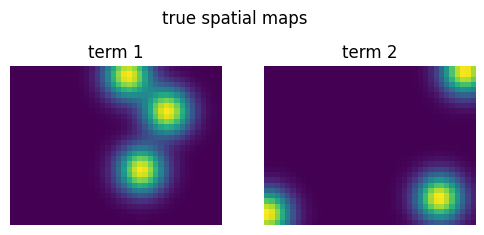

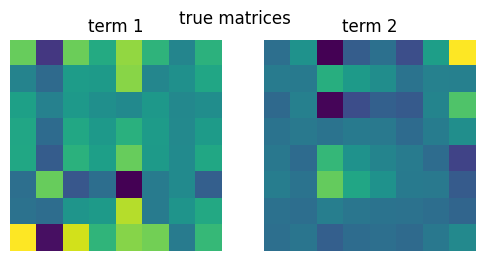

In [2]:
def show_maps(maps, title):
    """Plot one image per term, scaled so its strongest pixel is +1."""
    fig, axes = plt.subplots(1, len(maps), figsize=(3 * len(maps), 2.8))
    for r, (ax, m) in enumerate(zip(axes, maps, strict=True)):
        ax.imshow(m / m.flat[np.abs(m).argmax()], cmap="viridis")
        ax.set_title(f"term {r + 1}")
        ax.axis("off")
    fig.suptitle(title)
    plt.show()


def matrices(C, D):
    """Matrix C_r @ D_r.T of each term."""
    return np.stack(
        [C[:, r * L2 : (r + 1) * L2] @ D[:, r * L2 : (r + 1) * L2].T for r in range(R)]
    )


show_maps(spatial_maps(A0, B0, L1), "true spatial maps")
show_maps(matrices(C0, D0), "true matrices")

## Fit the model

In [3]:
model.check_uniqueness()

True

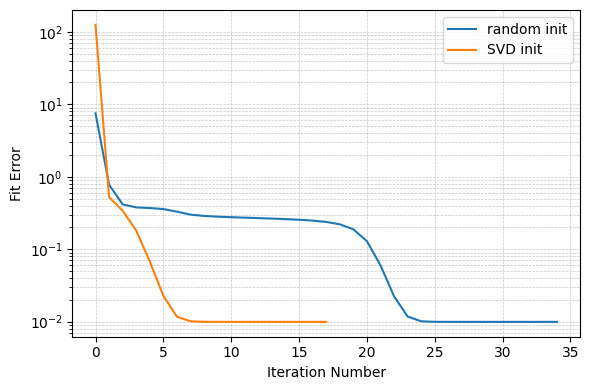

In [4]:
model.fit(T, algorithm="ALS", init="random", max_iter=1000, rel_tol=1e-10, abs_tol=0)
random_init_error = model.fit_error

model.fit(T, algorithm="ALS", init="svd", max_iter=1000, rel_tol=1e-10, abs_tol=0)
svd_init_error = model.fit_error

plot_error([random_init_error, svd_init_error], labels=["random init", "SVD init"])

## Check the result

Each term is recovered up to its position in the list and a scaling shared between its map
and its matrix (possibly negative):

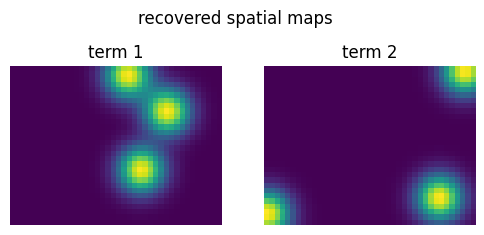

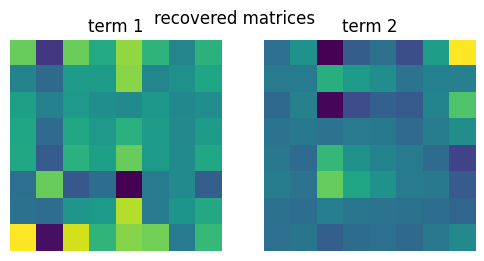

In [5]:
A, B, C, D = model.factors
show_maps(spatial_maps(A, B, L1), "recovered spatial maps")
show_maps(matrices(C, D), "recovered matrices")

In [6]:
np.linalg.norm(model.tensor - T0) / np.linalg.norm(T0)

np.float64(0.000764989699485169)